# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [12]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))
print(df.columns.tolist())



Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  
['neighbourhood', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'availability_365', 'revi

In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

Median prices:
room_type
Entire home/apt    163.420
Private room        78.575
Name: price, dtype: float64


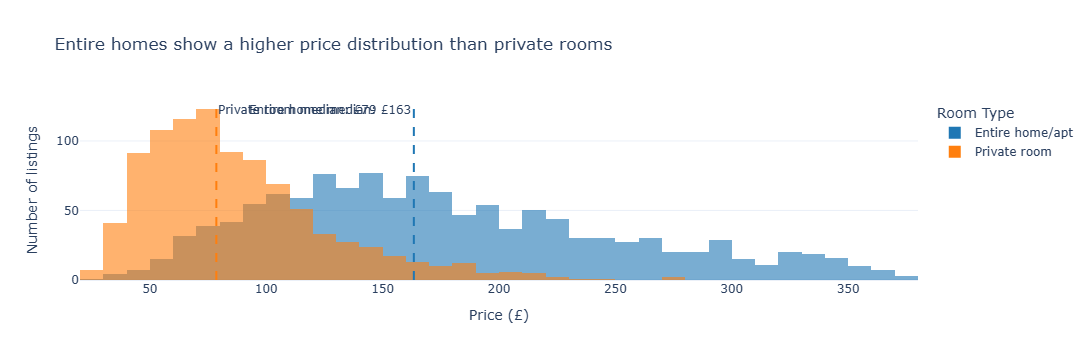

Note: Prices above £373 (95th percentile) were excluded to reduce the influence of extreme outliers.


In [5]:
# Task 1
# Exclude Shared rooms
hist_df = df_cap[
    df_cap['room_type'].isin(['Entire home/apt', 'Private room'])
].copy()

# Calculate median prices for each room type
medians = hist_df.groupby('room_type')['price'].median()

print("Median prices:")
print(medians)

import plotly.express as px

fig = px.histogram(
    hist_df,
    x='price',
    color='room_type',
    barmode='overlay',
    opacity=0.6,
    nbins=50,
    title='Entire homes show a higher price distribution than private rooms',
    labels={
        'price': 'Price (£)',
        'count': 'Number of listings',
        'room_type': 'Room Type'
    },
    color_discrete_map={
        'Entire home/apt': '#1f77b4',
        'Private room': '#ff7f0e'
    }
)

# Median reference lines
fig.add_vline(
    x=medians['Entire home/apt'],
    line_dash='dash',
    line_color='#1f77b4',
    annotation_text=f"Entire home median: £{medians['Entire home/apt']:.0f}",
    annotation_position='top left'
)

fig.add_vline(
    x=medians['Private room'],
    line_dash='dash',
    line_color='#ff7f0e',
    annotation_text=f"Private room median: £{medians['Private room']:.0f}",
    annotation_position='top right'
)

fig.update_layout(
    xaxis_title='Price (£)',
    yaxis_title='Number of listings',
    legend_title='Room Type',
    template='plotly_white'
)

fig.show()
print(f"Note: Prices above £{p95:.0f} (95th percentile) were excluded to reduce the influence of extreme outliers.")

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

In [13]:
# Task 2
# Remove listings with zero or missing reviews per month
activity_df = df[
    (df['reviews_per_month'] > 0) &
    (df['reviews_per_month'].notna())
].copy()

# Identify borough column
borough_col = 'neighbourhood'  
# Calculate median activity for each borough
borough_medians = (
    activity_df.groupby(borough_col)['reviews_per_month']
    .median()
    .sort_values(ascending=False)
)

# Identify the two most active boroughs
top_two = borough_medians.head(2)

print("Two busiest boroughs:")
print(top_two)


Two busiest boroughs:
neighbourhood
Tower Hamlets    1.75
Hackney          1.66
Name: reviews_per_month, dtype: float64


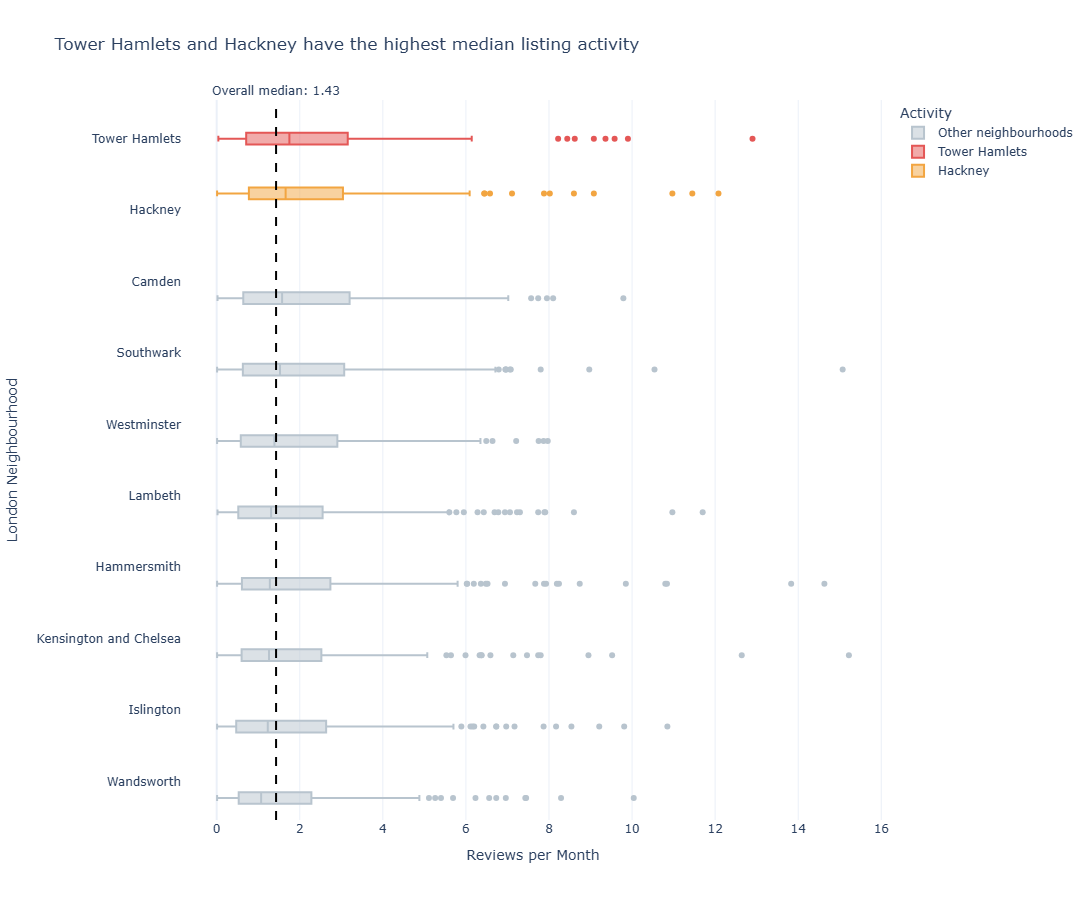

In [14]:
# Sort neighbourhoods by median activity
borough_order = borough_medians.index.tolist()

# Highlight the two busiest neighbourhoods
activity_df['Activity Group'] = activity_df[borough_col].apply(
    lambda x: x if x in top_two.index else 'Other neighbourhoods'
)

# Calculate overall median
overall_median = activity_df['reviews_per_month'].median()

# Create insight title
title = (
    f"{top_two.index[0]} and {top_two.index[1]} "
    "have the highest median listing activity"
)

fig = px.box(
    activity_df,
    x='reviews_per_month',
    y=borough_col,
    color='Activity Group',
    orientation='h',
    category_orders={borough_col: borough_order},
    color_discrete_map={
        top_two.index[0]: '#e45756',
        top_two.index[1]: '#f2a541',
        'Other neighbourhoods': '#b8c4ce'
    },
    points='outliers',
    title=title,
    labels={
        'reviews_per_month': 'Reviews per Month',
        borough_col: 'Neighbourhood',
        'Activity Group': 'Activity'
    }
)

# Overall median reference line
fig.add_vline(
    x=overall_median,
    line_dash='dash',
    line_color='black',
    annotation_text=f'Overall median: {overall_median:.2f}',
    annotation_position='top'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Reviews per Month',
    yaxis_title='London Neighbourhood',
    height=900
)

fig.show()